# Consumer Product Safety Project Capstone

This project analyzes consumer product-related injuries among children aged 0–17 in the United States in 2025. The analysis uses NEISS injury data, CPSC product recall data, and U.S. Census population estimates.

# Exploratory Data Analysis (EDA)

### Q1. Top 10 Products Associated with Childhood Injuries in 2025

This analysis uses NEISS sampling weights to identify the 10 products associated with the highest estimated number of childhood injuries in the United States.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

folder = '/content/drive/MyDrive/DATA205_Capstone/'

neiss_children = pd.read_csv(folder + 'neiss_children_clean.csv')
recalls_clean = pd.read_csv(folder + 'recalls_clean.csv')
population_clean = pd.read_csv('/content/drive/MyDrive/population_children_2025_processed.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


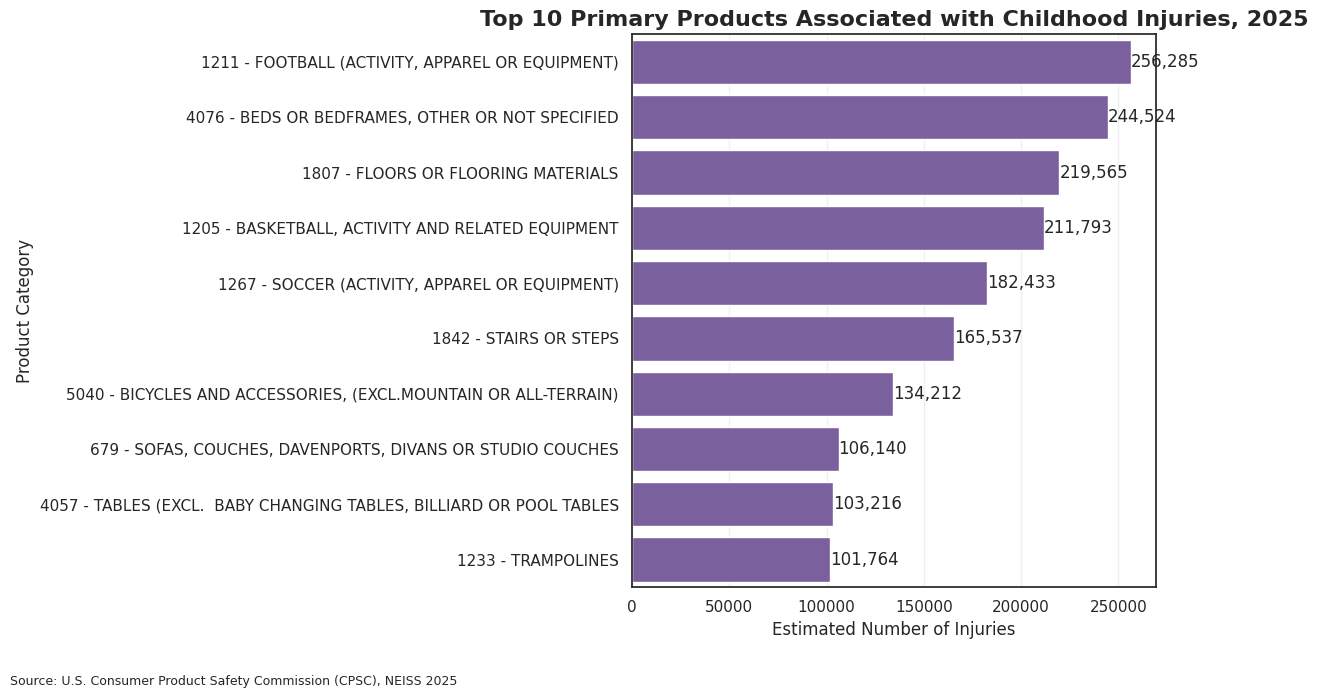

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
# Calculate estimated injuries by primary product
top_10_products = (
    neiss_children.groupby('product_1_decoded')['weight']
    .sum()
    .nlargest(10)
    .reset_index()
)

# Set graph style
sns.set_theme(style="white")

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_products,
    x='weight',
    y='product_1_decoded',
    color='#7856A6'
)

plt.title('Top 10 Primary Products Associated with Childhood Injuries, 2025',
          fontsize=16, fontweight='bold')

plt.xlabel('Estimated Number of Injuries')
plt.ylabel('Product Category')

for container in plt.gca().containers:
    plt.bar_label(container, fmt='{:,.0f}')

plt.figtext(
    0.01, 0.01,
    'Source: U.S. Consumer Product Safety Commission (CPSC), NEISS 2025',
    ha='left',
    fontsize=9
)

plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

### Q2. Top 10 Injury Diagnoses Among Children in 2025

This analysis uses NEISS weights to find the 10 most common injury diagnoses among children in the United States. "Other/Not Stated" is removed because it does not describe a specific injury.

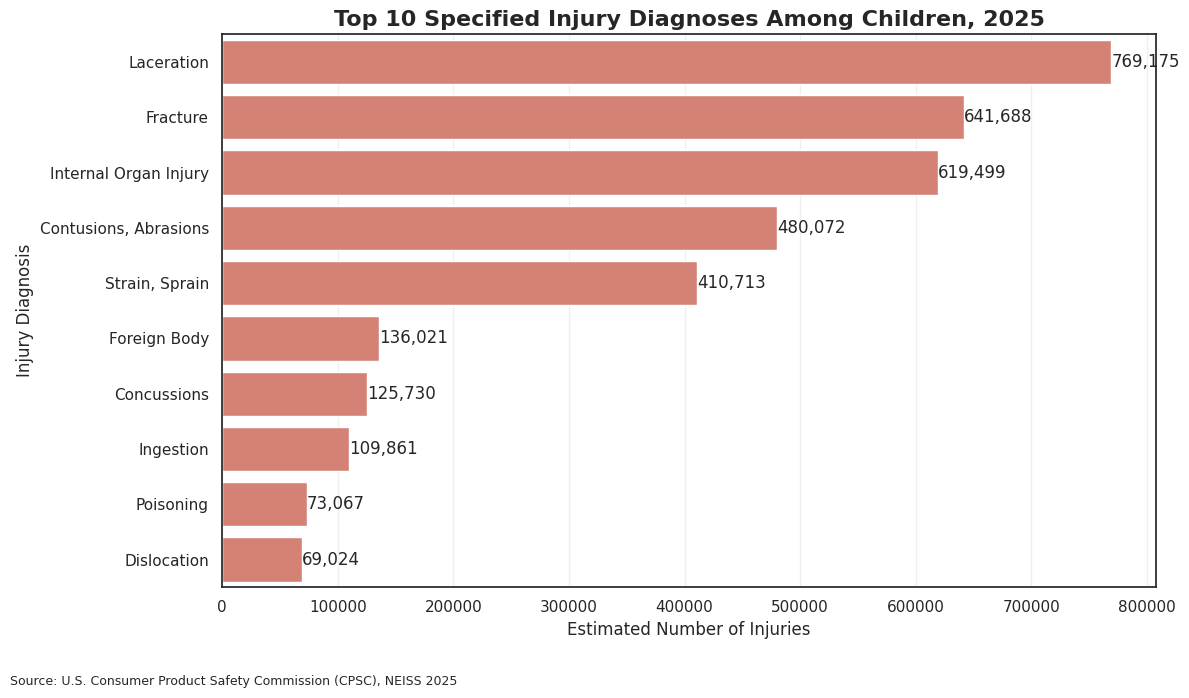

In [5]:
# Q2: Top 10 injury diagnoses among children in 2025

# Exclude unspecified diagnoses
diagnoses_1 = neiss_children[
    neiss_children['diagnosis_decoded'] != 'Other/Not Stated'
]

# Calculate estimated injuries by diagnosis
top_10_diagnoses = (
    diagnoses_1.groupby('diagnosis_decoded')['weight']
    .sum()
    .nlargest(10)
    .reset_index()
)

# Set graph style
sns.set_theme(style="white")
plt.figure(figsize=(12, 7))

# Create bar chart
sns.barplot(
    data=top_10_diagnoses,
    x='weight',
    y='diagnosis_decoded',
    color='#E47765'
)

# Add title and axis labels
plt.title(
    'Top 10 Specified Injury Diagnoses Among Children, 2025',
    fontsize=16,
    fontweight='bold'
)
plt.xlabel('Estimated Number of Injuries')
plt.ylabel('Injury Diagnosis')

# Display values on bars
for container in plt.gca().containers:
    plt.bar_label(container, fmt='{:,.0f}')

# Add data source
plt.figtext(
    0.01, 0.01,
    'Source: U.S. Consumer Product Safety Commission (CPSC), NEISS 2025',
    ha='left',
    fontsize=9
)

plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

### Q3. Top 10 Most Common Injured Body Parts Among Children in 2025

This analysis uses NEISS weights to find the 10 most commonly injured body parts among children in the United States. Only the primary injured body part is used. A treemap shows the results, with larger rectangles representing more estimated injuries

In [6]:
%pip install squarify

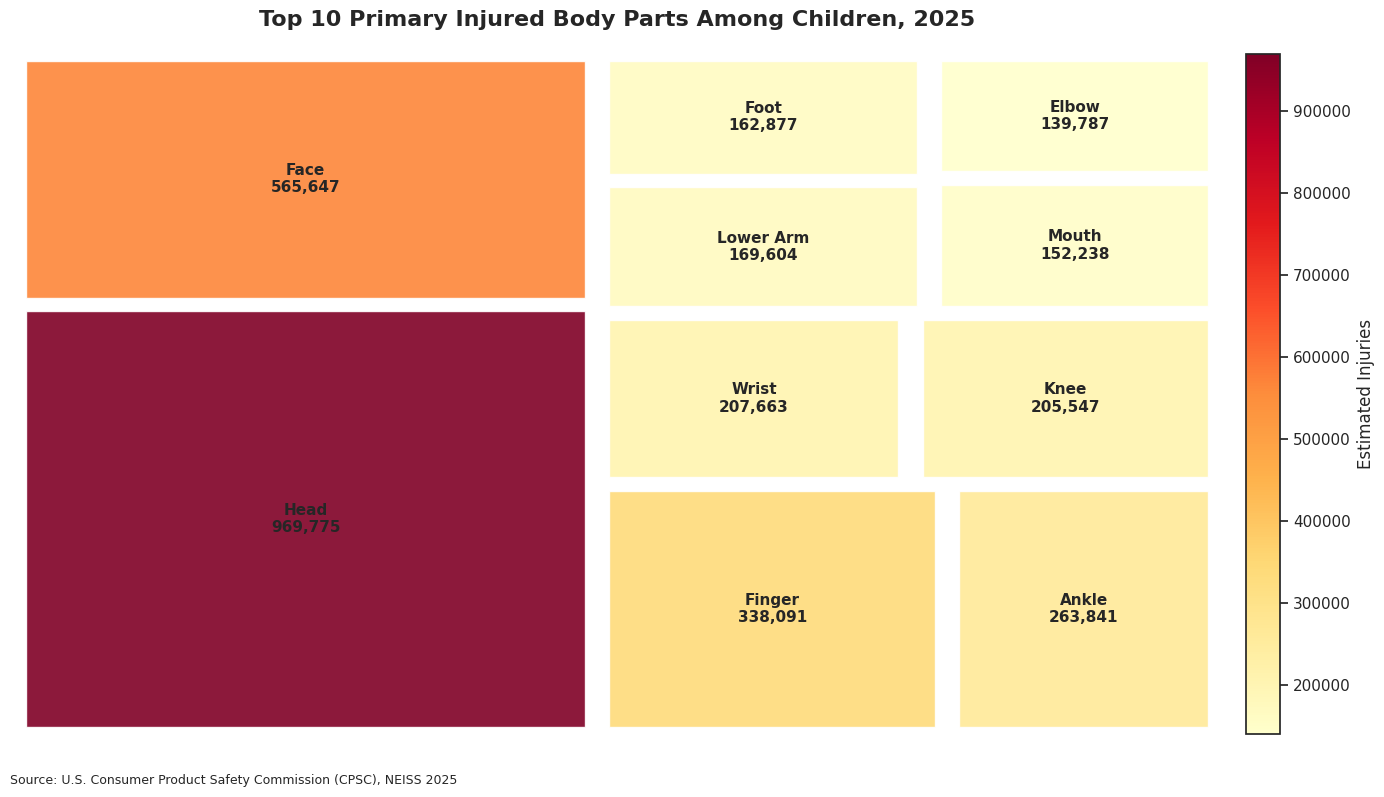

In [7]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import squarify

# Calculate estimated injuries by primary body part
top_10_body_parts = (
    neiss_children.groupby('body_part_decoded')['weight']
    .sum()
    .nlargest(10)
    .reset_index()
)

# Create labels
labels = [
    f"{name}\n{weight:,.0f}"
    for name, weight in zip(
        top_10_body_parts['body_part_decoded'],
        top_10_body_parts['weight']
    )
]

# Create a color scale based on estimated injuries
norm = mcolors.Normalize(
    vmin=top_10_body_parts['weight'].min(),
    vmax=top_10_body_parts['weight'].max()
)

cmap = plt.get_cmap('YlOrRd')

colors = [
    cmap(norm(value))
    for value in top_10_body_parts['weight']
]

# Create treemap
fig, ax = plt.subplots(figsize=(14, 8))

squarify.plot(
    sizes=top_10_body_parts['weight'],
    label=labels,
    color=colors,
    alpha=0.9,
    pad=3,
    text_kwargs={
        'fontsize': 11,
        'fontweight': 'bold'
    },
    ax=ax
)

# Add title
ax.set_title(
    'Top 10 Primary Injured Body Parts Among Children, 2025',
    fontsize=16,
    fontweight='bold',
    pad=20
)

# Hide axes
ax.axis('off')

# Add color scale
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label('Estimated Injuries')

# Add source
fig.text(
    0.01, 0.01,
    'Source: U.S. Consumer Product Safety Commission (CPSC), NEISS 2025',
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

### Q4. Most Common Injury Diagnoses by Age Group in 2025

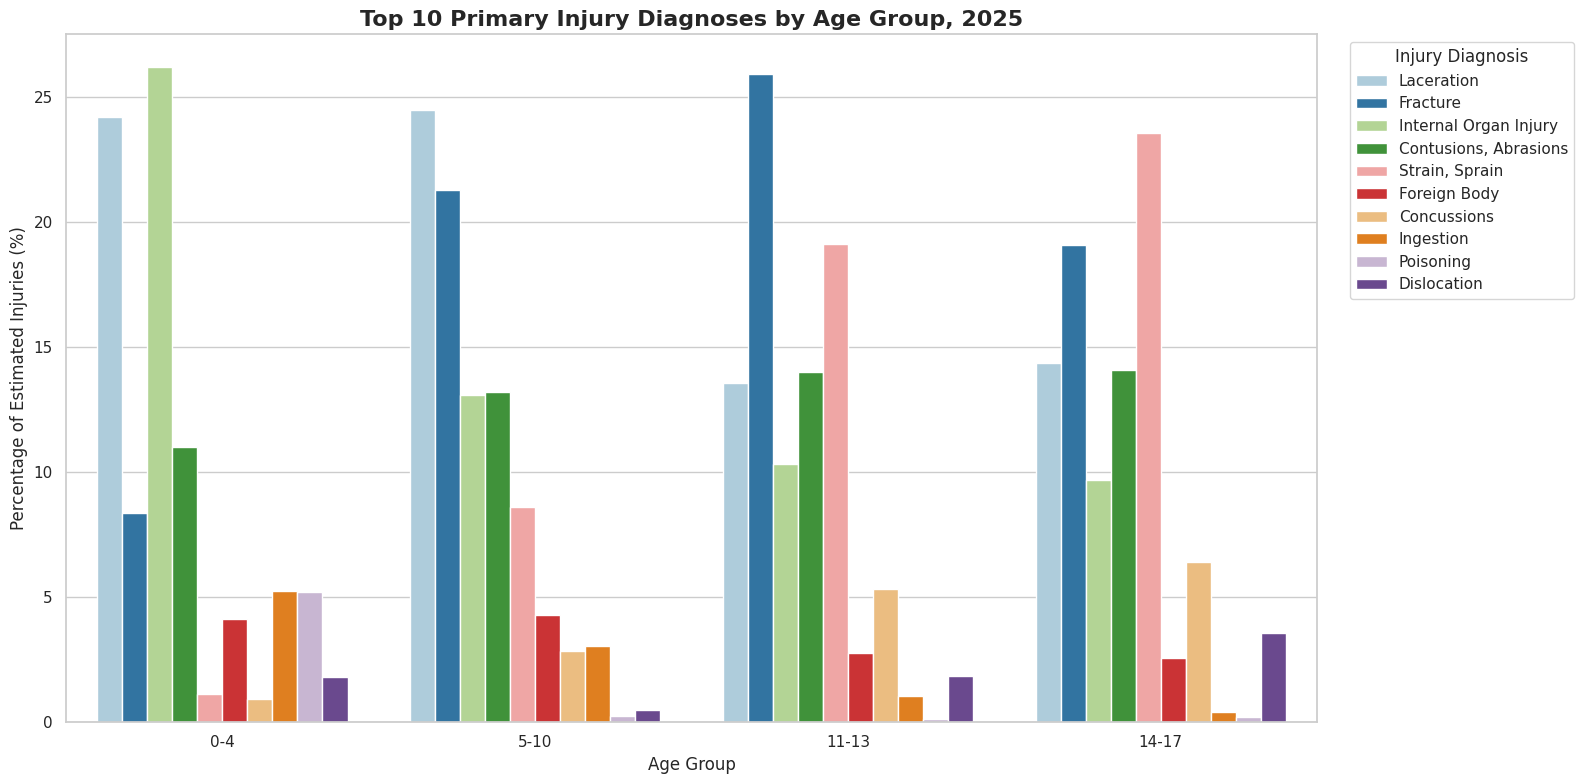

In [8]:

# Keep primary diagnoses and remove missing values
diagnoses = neiss_children.dropna(
    subset=['diagnosis_decoded']
).copy()

# Remove Other/Not Stated
diagnoses = diagnoses[
    diagnoses['diagnosis_decoded'] != 'Other/Not Stated'
]

# Select the top 10 primary diagnoses
top_10_diagnoses = (
    diagnoses.groupby('diagnosis_decoded')['weight']
    .sum()
    .nlargest(10)
    .index
)

# Calculate estimated injuries by age group and diagnosis
diagnosis_by_age = (
    diagnoses.groupby(['age_group', 'diagnosis_decoded'])['weight']
    .sum()
    .reset_index()
)

# Calculate total estimated injuries for each age group
age_totals = (
    diagnoses.groupby('age_group')['weight']
    .sum()
    .reset_index(name='total_weight')
)

# Add age group totals
diagnosis_by_age = diagnosis_by_age.merge(
    age_totals,
    on='age_group'
)

# Calculate weighted percentages
diagnosis_by_age['percentage'] = (
    diagnosis_by_age['weight'] /
    diagnosis_by_age['total_weight'] * 100
)

# Keep only the top 10 diagnoses
diagnosis_by_age = diagnosis_by_age[
    diagnosis_by_age['diagnosis_decoded'].isin(top_10_diagnoses)
]

# Set age group order
age_order = ['0-4', '5-10', '11-13', '14-17']

# Create grouped bar chart
sns.set_theme(style='whitegrid')
plt.figure(figsize=(16, 8))

sns.barplot(
    data=diagnosis_by_age,
    x='age_group',
    y='percentage',
    hue='diagnosis_decoded',
    order=age_order,
    hue_order=top_10_diagnoses,
    palette='Paired'
)

# Add title and labels
plt.title(
    'Top 10 Primary Injury Diagnoses by Age Group, 2025',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Age Group')
plt.ylabel('Percentage of Estimated Injuries (%)')

# Place legend outside the chart
plt.legend(
    title='Injury Diagnosis',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

### Q5: Estimated Injury Rates by Age Group

**Research Question:** Which age group has the highest estimated injury rate per 100,000 children in 2025?

In [9]:


# Keep only children ages 0-17
population_clean['Age'] = pd.to_numeric(
    population_clean['Age'], errors='coerce'
)

children_population = population_clean[
    population_clean['Age'].between(0, 17)
].copy()

# Create age groups using np.where
children_population['age_group'] = np.where(
    children_population['Age'] <= 4, '0-4',
    np.where(
        children_population['Age'] <= 10, '5-10',
        np.where(
            children_population['Age'] <= 13, '11-13',
            '14-17'
        )
    )
)

# Calculate total population by age group
population_by_age = (
    children_population.groupby('age_group')['Population_2025']
    .sum()
    .reset_index(name='population')
)

# Calculate estimated injuries using NEISS weights
injuries_by_age = (
    neiss_children.groupby('age_group')['weight']
    .sum()
    .reset_index(name='estimated_injuries')
)

# Combine NEISS and Census data
injury_rates = injuries_by_age.merge(
    population_by_age,
    on='age_group'
)

# Calculate injury rates per 100,000 children
injury_rates['injury_rate'] = (
    injury_rates['estimated_injuries'] /
    injury_rates['population'] * 100000
)

# Display results
display(injury_rates)

# Create bar chart
age_order = ['0-4', '5-10', '11-13', '14-17']

import plotly.express as px

# Create interactive bar chart
fig = px.bar(
    injury_rates,
    x='age_group',
    y='injury_rate',
    color='age_group',
    category_orders={
        'age_group': ['0-4', '5-10', '11-13', '14-17']
    },
    color_discrete_sequence=[
        '#253B73', '#25A6A1', '#D9A441', '#D47D78'
    ],
    text='injury_rate',
    title='Estimated Injury Rates by Age Group Among Children, 2025',
    labels={
        'age_group': 'Age Group',
        'injury_rate': 'Estimated Injuries per 100,000 Children'
    }
)

fig.update_traces(
    texttemplate='%{text:,.0f}',
    textposition='outside'
)

fig.update_layout(
    template='plotly_white',
    showlegend=False
)

fig.show()

,age_group,estimated_injuries,population,injury_rate
0,0-4,1.469070e+06,18491867.0,7944.414019
1,11-13,7.726868e+05,12325571.0,6268.973724
2,14-17,1.066682e+06,17296677.0,6166.975624
3,5-10,1.246463e+06,23907233.0,5213.748924


### Q6: Serious Emergency Department Outcomes by Age Group

 How do serious emergency department outcomes differ across age groups (0–4, 5–10, 11–13, and 14–17)?



looking for the emergency department outcome

In [10]:
# Check emergency department outcomes
neiss_children['disposition_decoded'].value_counts()

,count
disposition_decoded,
Treated and Released,153300
Hospitalized,5775
Left Without Being Seen,2156
Treated and Transferred,1237
Held for Observation,361
Fatality,57
Unknown,8


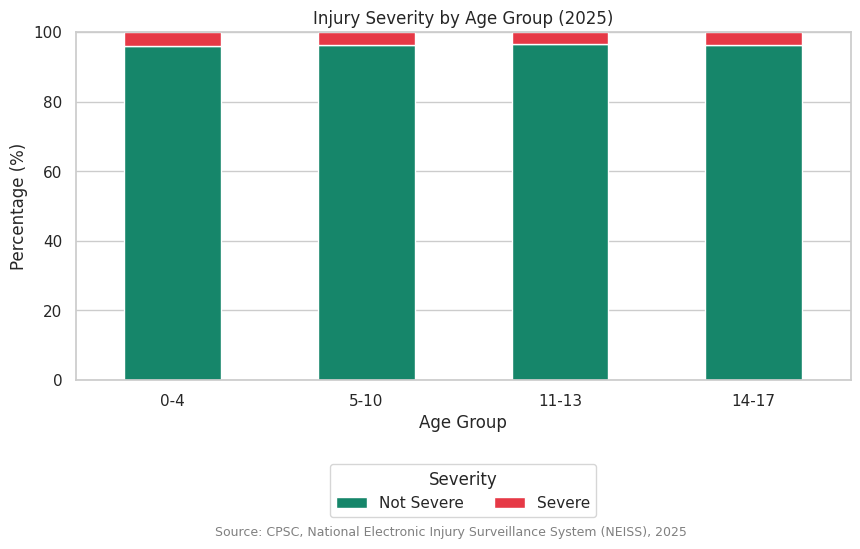

In [11]:


# Group injuries by age and severity
severity_age_by_group = (
    neiss_children[neiss_children['severity'] != 'Unknown']
    .groupby(['age_group', 'severity'])['weight']
    .sum()
    .reset_index()
)

# Calculate percentages for each age group
severity_age_by_group['percent'] = (
    severity_age_by_group['weight'] /
    severity_age_by_group.groupby('age_group')['weight'].transform('sum')
) * 100


# Create stacked bar chart
severity_age_by_group.pivot(
    index='age_group',
    columns='severity',
    values='percent'
).loc[
    ['0-4', '5-10', '11-13', '14-17'],
    ['Not Severe', 'Severe']
].plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    color=['#16866A', '#E63946']  # Green and bright red
)



plt.title('Injury Severity by Age Group (2025)')
plt.xlabel('Age Group')
plt.ylabel('Percentage (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)

# Place legend below the chart
plt.legend(
    title='Severity',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.22),
    ncol=2
)

# Leave space for legend and source
plt.subplots_adjust(bottom=0.30)

# Add data source
plt.figtext(
    0.5, 0.04,
    'Source: CPSC, National Electronic Injury Surveillance System (NEISS), 2025',
    ha='center',
    fontsize=9,
    color='gray'
)

plt.show()


In [12]:


# Create stacked bar chart
fig = px.bar(
    severity_age_by_group,
    x='age_group',
    y='percent',
    color='severity',
    barmode='stack',
    category_orders={
        'age_group': ['0-4', '5-10', '11-13', '14-17'],
        'severity': ['Not Severe', 'Severe']
    },
    color_discrete_map={
        'Not Severe': '#16866A',
        'Severe': '#E63946'
    },
    title='Injury Severity by Age Group (2025)',
    labels={
        'age_group': 'Age Group',
        'percent': 'Percentage (%)',
        'severity': 'Severity'
    },
    hover_data={'weight': ':,.0f'}
)

# Customize chart
fig.update_layout(
    template='plotly_white',
    yaxis_range=[0, 100],
    bargap=0.3,
    legend=dict(
        orientation='h',
        yanchor='top',
        y=-0.2,
        xanchor='center',
        x=0.5
    ),
    margin=dict(b=130)
)

# Add data source
fig.add_annotation(
    text='Source: CPSC, National Electronic Injury Surveillance System (NEISS), 2025',
    xref='paper',
    yref='paper',
    x=0.5,
    y=-0.38,
    showarrow=False,
    font=dict(size=11, color='gray')
)

fig.show()


Most Common Hazards in Product Recalls (2025)

Q7: What are the most common hazards associated with recalled products in 2025?

The CPSC recall dataset does not have an age column to show which products are for children or adults. I thought about using words like "toys," "children," or "baby" to find children's products. However, this could leave out many products that children also use. Because of this, I decided to use all product recalls from 2025 instead of only children's products. This means my recall analysis includes products for both children and adults.

In [13]:
recalls_clean.columns

Index(['recall_number', 'product_safety_warning_number', 'date',
       'product_safety_warning_date', 'recall_heading', 'name_of_product',
       'description', 'hazard_description', 'consumer_action',
       'original_product_safety_warning_announcement', 'remedy_type', 'units',
       'incidents', 'remedy', 'sold_at_label', 'sold_at', 'importers',
       'manufacturers', 'distributors', 'manufactured_in', 'custom_label',
       'custom_field', 'countries_clean', 'Laceration', 'Crash', 'Impact',
       'Overheating', 'Head Injury', 'Skin Irritation', 'Infection',
       'Pressure / Rupture', 'Collapse', 'Structural Failure',
       'Circulation Restriction', 'Rollover', 'Equipment Failure',
       'Unexpected Activation'],
      dtype='object')

In [14]:
# Select the hazard categories
hazard_columns = recalls_clean.columns[23:]

# Count recalls for each hazard
hazard_counts = recalls_clean[hazard_columns].sum().sort_values(ascending=False)

# Display results
print(hazard_counts)

Overheating                45
Laceration                 29
Crash                      25
Impact                      9
Infection                   8
Head Injury                 6
Equipment Failure           6
Collapse                    4
Skin Irritation             2
Pressure / Rupture          1
Structural Failure          1
Circulation Restriction     1
Rollover                    1
Unexpected Activation       1
dtype: int64


In [15]:
hazard_keywords = {
    column: None
    for column in recalls_clean.columns[23:]
}

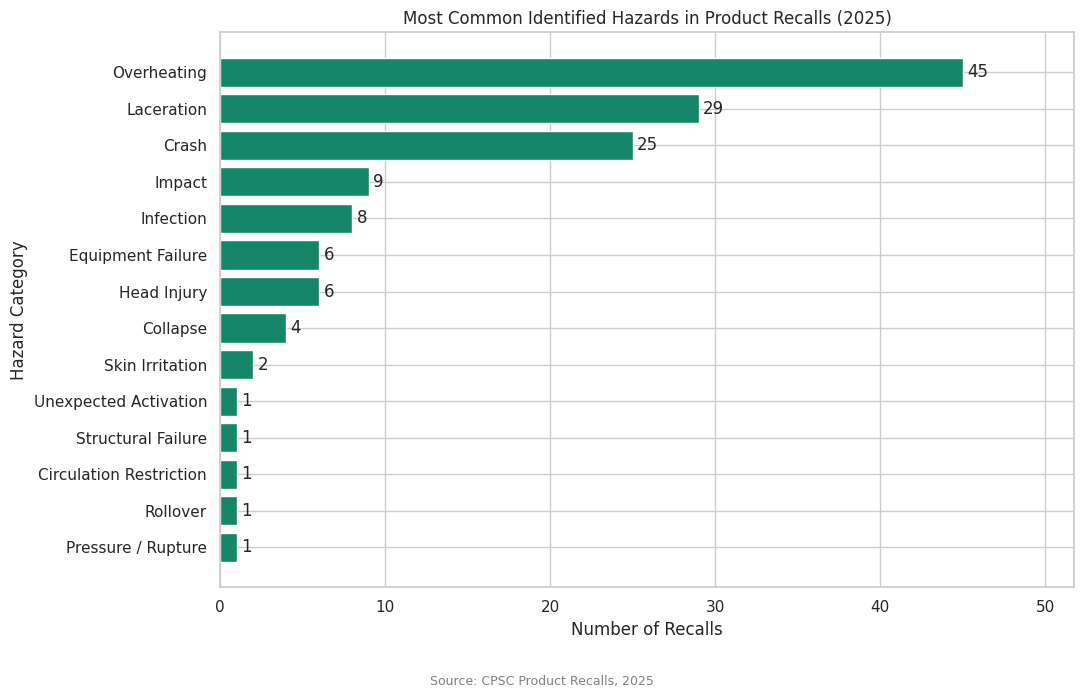

In [16]:

# Count recalls by hazard category
hazard_counts = (
    recalls_clean[list(hazard_keywords.keys())]
    .sum()
    .sort_values(ascending=True)
)

# Create horizontal bar chart
plt.figure(figsize=(11, 7))

bars = plt.barh(
    hazard_counts.index,
    hazard_counts.values,
    color='#16866A'
)

# Add count labels
plt.bar_label(bars, padding=3)

plt.title('Most Common Identified Hazards in Product Recalls (2025)')
plt.xlabel('Number of Recalls')
plt.ylabel('Hazard Category')
plt.xlim(0, hazard_counts.max() * 1.15)

# Add data source
plt.figtext(
    0.5, 0.01,
    'Source: CPSC Product Recalls, 2025',
    ha='center',
    fontsize=9,
    color='gray'
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

Monthly Product Recalls in 2025

Q8: How did product recalls change by month in 2025?

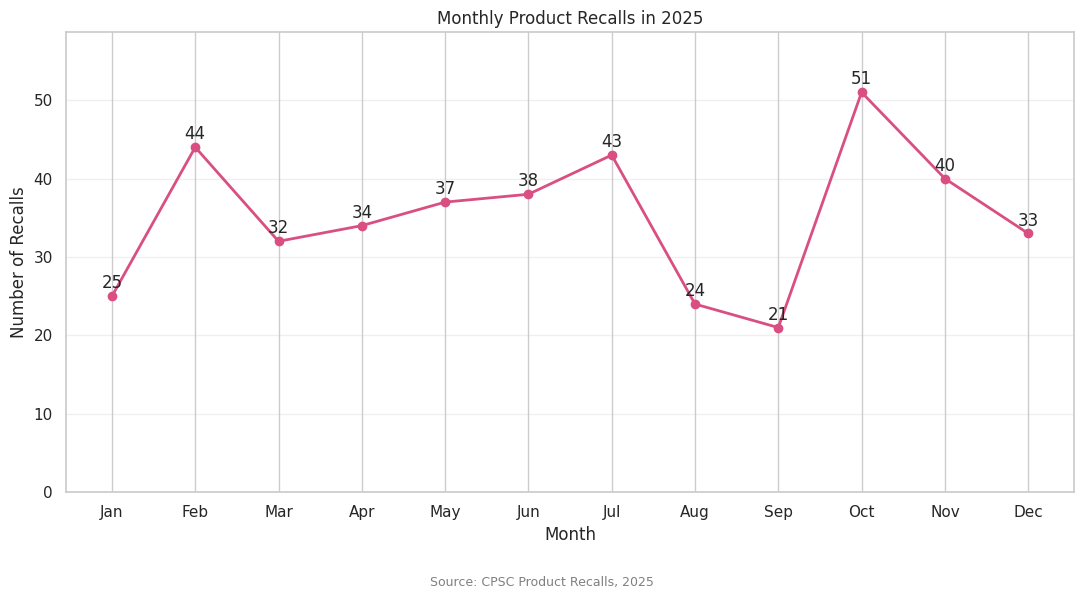

In [17]:
recalls_clean['date'] = pd.to_datetime(recalls_clean['date'], errors='coerce')
# Count recalls by month
monthly_recalls = (
    recalls_clean.groupby(recalls_clean['date'].dt.month)
    .size()
    .reindex(range(1, 13), fill_value=0)
)

# Create line chart
plt.figure(figsize=(11, 6))

plt.plot(
    monthly_recalls.index,
    monthly_recalls.values,
    marker='o',
    color='#D94F82',
    linewidth=2
)

# Add count labels
for month, count in monthly_recalls.items():
    plt.text(month, count + 1, str(count), ha='center')

plt.title('Monthly Product Recalls in 2025')
plt.xlabel('Month')
plt.ylabel('Number of Recalls')
plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.ylim(0, monthly_recalls.max() * 1.15)
plt.grid(axis='y', alpha=0.3)

plt.figtext(
    0.5, 0.01,
    'Source: CPSC Product Recalls, 2025',
    ha='center',
    fontsize=9,
    color='gray'
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


 Recall Hazards by Country of Manufacture (2025)

 Q9:How do recall hazards differ by country of manufacture?



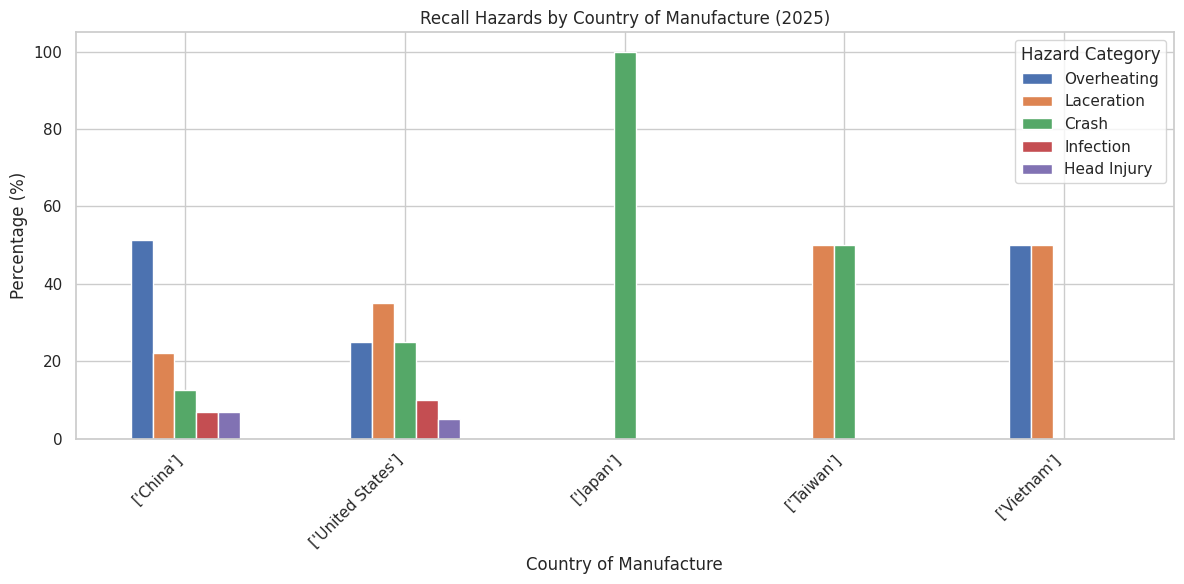

In [18]:

# Separate countries stored in lists
recall_hazards_by_country = recalls_clean.explode('countries_clean')

# Count hazards by country
hazard_counts = recall_hazards_by_country.groupby('countries_clean')[list(hazard_keywords)].sum()

# Select the top 5 countries
top_countries = hazard_counts.sum(axis=1).nlargest(5).index
hazard_counts = hazard_counts.loc[top_countries]

# Select the top 5 hazard categories
top_hazards = hazard_counts.sum().nlargest(5).index
hazard_counts = hazard_counts[top_hazards]

# Calculate hazard percentages by country
hazard_percentages = hazard_counts.div(
    hazard_counts.sum(axis=1), axis=0
) * 100

# Create grouped bar chart
hazard_percentages.plot(kind='bar', figsize=(12, 6))

plt.title('Recall Hazards by Country of Manufacture (2025)')
plt.xlabel('Country of Manufacture')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Hazard Category', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()